---
title: "Лабораторна робота 6. Формалізація причинного питання та побудова причинної моделі дослідження"
description: "Машинне навчання та методи вилучення знань | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mlkdd-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---


::: {.callout-note}
## Місце лабораторної роботи в курсі

ЛР1–ЛР5 сформували послідовність *Research Specification v0.1 → Experiment Design v0.2 → Validation & Evidence Audit v0.3 → Structure Discovery & Validation v0.4 → Explanation Audit v0.5*.

У ЛР6 переходимо від пояснення *прогнозу моделі* до формалізації *ефекту втручання*. Підсумковий артефакт -- *Causal Research Specification v0.6*. Методи складного оцінювання причинних ефектів залишаємо для ЛР7.
:::

## Мета роботи

Набути практичних навичок постановки причинного дослідницького питання, визначення втручання, результату та цільового ефекту, побудови причинного графа (DAG), виявлення змішування і систематичної помилки відбору, обґрунтування набору коригування та перевірки базових умов ідентифікації.

## Завдання роботи

1. Відрізнити спостережувану асоціацію від причинного ефекту.
2. Сформулювати потенційні наслідки та цільовий параметр ATE.
3. Побудувати DAG для контрольованого навчального прикладу.
4. Визначити конфаундер, медіатор та колайдер.
5. Порівняти наївну різницю середніх і коригування на конфаундер.
6. Продемонструвати систематичну помилку відбору через колайдер.
7. Перевірити перекриття груп (overlap) і обмеження позитивності.
8. Сформувати причинну постановку власного дисертаційного дослідження.

## Теоретичні відомості

Для бінарного втручання $T$ потенційні наслідки $Y(1)$ та $Y(0)$ визначають результат для однієї одиниці за альтернативних станів втручання. Середній причинний ефект (average treatment effect, ATE):

$$
ATE=\mathbb{E}[Y(1)-Y(0)].
$$

Спостережувана різниця

$$
\mathbb{E}[Y\mid T=1]-\mathbb{E}[Y\mid T=0]
$$

загалом не дорівнює ATE через змішування (confounding), відбір та інші механізми [@pearl2009causality; @hernan2020causal].

За консистентності, умовної обмінності $Y(t)\perp T\mid C$ та позитивності причинний ефект ідентифікується через стандартизацію:

$$
ATE=\mathbb{E}_{C}\left[\mathbb{E}(Y\mid T=1,C)-\mathbb{E}(Y\mid T=0,C)\right].
$$

*Ідентифікація* відповідає на питання, чи можна виразити причинний параметр через спостережуваний розподіл; *оцінювання* -- як обчислити його за скінченною вибіркою; *валідація* -- які припущення та джерела похибки контролюємо.

### Методологічна схема

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Причинне<br/>питання") --> B("Втручання та<br/>результат")
 B --> C("DAG і<br/>припущення")
 C --> D("Ідентифікація<br/>ефекту")
 D --> E("Аудит<br/>позитивності")
 E --> F("Causal Research<br/>Specification v0.6")
```

# Частина I. Навчальний експеримент

## 1. Причинне питання та протокол

**Ситуація.** Освітня платформа надсилає частині користувачів персоналізовану рекомендацію навчального матеріалу. Дослідницьке питання: *чи збільшує надсилання рекомендації подальший показник навчальної активності?*

Визначення:

- Одиниця аналізу -- користувач платформи.
- $T=1$ -- рекомендацію надіслано, $T=0$ -- не надіслано.
- $Y$ -- числовий показник активності після визначеного інтервалу.
- $C$ -- мотивація до початку втручання, виміряна до призначення рекомендації.
- Цільовий параметр -- $ATE$ у заданій популяції користувачів.

У цьому навчальному генераторі припускаємо відсутність інтерференції між користувачами. Для реальних соціальних мереж це припущення може бути неприйнятним.

### Завдання 1.1

Поясніть, чому запитання «Хто частіше отримує рекомендацію?» і «Який ефект має рекомендація?» потребують різних дослідницьких протоколів.

## 2. Причинна модель і DAG

Для контрольованого прикладу припускаємо:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 C("Мотивація C") --> T("Рекомендація T")
 C --> Y("Активність Y")
 T --> Y
```

Тут $C$ -- конфаундер (спільна причина $T$ та $Y$). Шлях $T\leftarrow C\to Y$ є *задньодверним* (backdoor path). Для загального ефекту $T$ на $Y$ коригування на $C$ блокує цей шлях за прийнятого графа.

### Завдання 2.1

Запишіть, чому $C$ допустимо включати до набору коригування. Наведіть приклад змінної, яку *не слід* включати автоматично (наприклад, медіатора, що виникає після рекомендації).

## 3. Генерація синтетичних даних

Використаємо структурний генератор:

$$
P(T=1\mid C)=\sigma(-0.3+1.4C),
\qquad \sigma(z)=\frac{1}{1+e^{-z}}.
$$

$$
Y(0)=2+1.8C+\varepsilon,\qquad Y(1)=Y(0)+1.5.
$$

Справжній ATE у генераторі дорівнює $1.5$, але для оцінювання ми використовуємо лише фактично спостережуваний $Y$.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

SEED = 42
rng = np.random.default_rng(SEED)
n = 5000

C = rng.normal(size=n)
propensity = 1 / (1 + np.exp(-(-0.3 + 1.4 * C)))
T = rng.binomial(1, propensity)
eps = rng.normal(size=n)
Y0 = 2 + 1.8 * C + eps
Y1 = Y0 + 1.5
Y = np.where(T == 1, Y1, Y0)

df = pd.DataFrame({"C": C, "T": T, "Y": Y})
true_ate = float(np.mean(Y1 - Y0))  # Лише контроль генератора
print("Розмір вибірки:", df.shape)
display(df.groupby("T")[["C", "Y"]].agg(["mean", "std"]).round(3))


Розмір вибірки: (5000, 3)


C             Y       
    mean    std   mean    std
T                            
0 -0.458  0.870  1.183  1.864
1  0.552  0.859  4.473  1.848

### Завдання 3.1

Які змінні доступні в реальному спостережувальному наборі даних, а які -- лише в нашому генераторі? Чому не можна обчислити індивідуальний ефект для реального користувача як різницю двох спостережень?

## 4. Наївна асоціація та коригування

Спочатку обчислимо спостережувану різницю середніх між групами, а потім застосуємо регресійне коригування на $C$. У нашому синтетичному генераторі лінійна специфікація результату є коректною. Для реальних даних це потрібно окремо обґрунтовувати.


,Оцінка,Значення
0,Наївна асоціація,3.290
1,Коригування на C,1.463
2,Справжній ATE (генератор),1.500


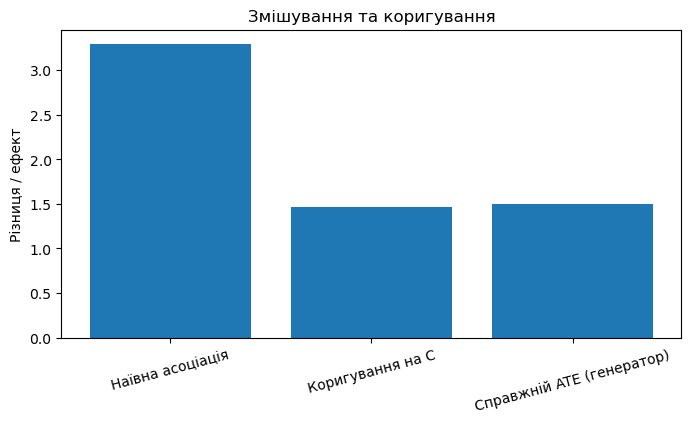

In [2]:
naive_difference = (
    df.loc[df["T"] == 1, "Y"].mean()
    - df.loc[df["T"] == 0, "Y"].mean()
)

outcome_model = LinearRegression()
outcome_model.fit(df[["T", "C"]], df["Y"])
adjusted_effect = float(outcome_model.coef_[0])

comparison = pd.DataFrame({
    "Оцінка": ["Наївна асоціація", "Коригування на C", "Справжній ATE (генератор)"],
    "Значення": [naive_difference, adjusted_effect, true_ate]
})
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(comparison["Оцінка"], comparison["Значення"])
ax.set(ylabel="Різниця / ефект", title="Змішування та коригування")
ax.tick_params(axis="x", rotation=15)
plt.show()


### Завдання 4.1

Порівняйте три величини. Чому наївна різниця не оцінює ATE у цьому прикладі? Чому близькість скоригованої оцінки до справжнього ATE не є доказом відсутності невиміряного змішування в реальному дослідженні?

## 5. Ручний приклад стандартизації

Нехай конфаундер $C$ бінарний, а частки його рівнів у цільовій популяції однакові.

| $C$ | $E(Y\mid T=0,C)$ | $E(Y\mid T=1,C)$ | Різниця |
|---|---:|---:|---:|
| 0 | 2 | 4 | 2 |
| 1 | 7 | 9 | 2 |

Тоді за припущень ідентифікації:

$$
ATE=0.5(4-2)+0.5(9-7)=2.
$$

### Завдання 5.1

Обчисліть ATE, якщо $P(C=0)=0.7$, $P(C=1)=0.3$, а різниці у двох стратах дорівнюють відповідно $2$ та $4$. Поясніть, чому потрібен розподіл $C$ саме в цільовій популяції.

## 6. Колайдер і систематична помилка відбору

Створимо незалежні $T$ і $Y$ без причинного зв'язку. Нехай одиниця потрапляє до аналізованої вибірки, якщо $S=1$ за правилом $S=(T=1)\lor(Y=1)$.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 T("T") --> S("Відбір S")
 Y("Y") --> S
```

Умовлення на колайдер $S$ створює асоціацію навіть тоді, коли у вихідній популяції її немає.


In [3]:
rng_selection = np.random.default_rng(SEED + 1)
n_sel = 100_000
T_sel = rng_selection.binomial(1, 0.5, size=n_sel)
Y_sel = rng_selection.binomial(1, 0.5, size=n_sel)
S_sel = (T_sel == 1) | (Y_sel == 1)

population = pd.DataFrame({"T": T_sel, "Y": Y_sel})
selected = population.loc[S_sel]
print("Повна популяція:")
display(population.groupby("T")["Y"].mean().round(3))
print("Після відбору S=1:")
display(selected.groupby("T")["Y"].mean().round(3))


Повна популяція:


T
0    0.500
1    0.498
Name: Y, dtype: float64

Після відбору S=1:


T
0    1.000
1    0.498
Name: Y, dtype: float64

### Завдання 6.1

Чому залежність між $T$ і $Y$ у відібраній вибірці не можна інтерпретувати як причинний ефект? Наведіть приклад подібного відбору в даних соціальних мереж або освітньої аналітики.

## 7. Позитивність і перекриття

Позитивність (positivity) означає, що для релевантних значень конфаундера існує ненульова ймовірність обох рівнів втручання:

$$
0<P(T=1\mid C=c)<1.
$$

У реальному дослідженні істинні propensity scores невідомі, тому їх оцінюють і перевіряють перекриття. У синтетичному прикладі ми можемо використати відомі ймовірності генератора лише як контроль.


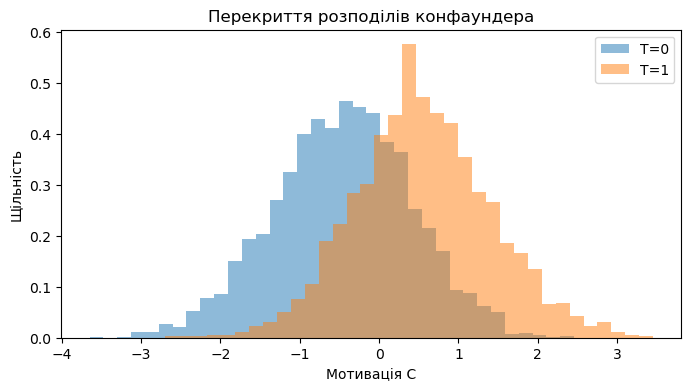

Частка P(T=1|C) < 0.05: 0.031
Частка P(T=1|C) > 0.95: 0.011


In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for treatment, label in [(0, "T=0"), (1, "T=1")]:
    ax.hist(C[T == treatment], bins=35, density=True,
            alpha=0.5, label=label)
ax.set(xlabel="Мотивація C", ylabel="Щільність",
       title="Перекриття розподілів конфаундера")
ax.legend()
plt.show()

print("Частка P(T=1|C) < 0.05:", round(float(np.mean(propensity < 0.05)), 3))
print("Частка P(T=1|C) > 0.95:", round(float(np.mean(propensity > 0.95)), 3))


### Завдання 7.1

Поясніть різницю між *теоретичною позитивністю* та *практичним перекриттям*. Що станеться, якщо для частини користувачів рекомендацію майже ніколи не надсилають?

## 8. Аудит причинної ідентифікації

Заповніть матрицю, спираючись на DAG і результати експерименту.

| Припущення або загроза | У навчальному генераторі | Що можна перевірити на реальних даних? |
|---|---|---|
| Консистентність втручання | $T$ має два однозначні стани | Опис протоколу та версій втручання |
| Умовна обмінність | Після коригування на $C$ | Невиміряне змішування не доводиться відсутнім |
| Позитивність | Обидва стани мають ненульову ймовірність | Оцінити overlap та крайні propensity |
| Відбір | У головному генераторі відбору немає | Визначити механізм включення у вибірку |
| Інтерференція | Відсутня за припущенням | Для мережевих даних часто критична |
| Часова послідовність | $C$ до $T$, $Y$ після $T$ | Перевірити часові позначки |

### Завдання 8.1

Сформулюйте *допустиме* причинне твердження для синтетичного прикладу та окремо -- твердження, яке було б надмірним за наявності лише спостережувальних даних без обґрунтованого DAG.

# Частина II. Перенесення на дисертаційне дослідження

## 9. Від RQ до причинного питання

Використайте артефакти ЛР1–ЛР5. Якщо початкове питання було прогнозним, сформулюйте окреме причинне питання, не підмінюючи його SHAP-атрибуціями чи коефіцієнтами ML-моделі.

Приклад: замість *«Які ознаки прогнозують зниження активності?»* -- *«Чи змінює введення конкретного механізму модерації подальшу частку координованих повідомлень?»*

## 10. Операціоналізація втручання та результату

| Компонент | Визначення для дисертації |
|---|---|
| Одиниця аналізу | |
| Цільова популяція | |
| $T=1$ | |
| $T=0$ | |
| Час призначення втручання | |
| Результат $Y$ та горизонт вимірювання | |
| Цільовий estimand (ATE/ATT/інший) | |
| Можлива інтерференція | |

## 11. Причинний граф та набір коригування

Побудуйте DAG із щонайменше одним можливим конфаундером. Якщо предметна область передбачає медіатор чи колайдер -- покажіть їх окремо. Вкажіть, які змінні спостережувані, а які потенційно невиміряні.

Обґрунтуйте набір коригування для *загального ефекту*, не включаючи автоматично всі доступні змінні. Зазначте, чи задовольняє запропонований набір backdoor criterion за прийнятим графом.

## 12. Припущення та ідентифікованість

Опишіть консистентність, обмінність, позитивність, відбір, часовий порядок і можливу інтерференцію. Для кожного припущення вкажіть: предметне обґрунтування; емпіричну діагностику, якщо можлива; наслідок порушення.

Якщо причинний ефект за наявних даних *не ідентифікується*, це є коректним науковим результатом аудиту. Не замінюйте відсутню ідентифікацію складнішою ML-моделлю.

## 13. План мінімальної перевірки

За наявності придатних даних заплануйте порівняння наївної асоціації та простої скоригованої оцінки. Якщо даних поки немає, опишіть відтворюваний синтетичний експеримент і критерії майбутньої перевірки.

## 14. Підсумковий артефакт -- Causal Research Specification v0.6

Підготуйте стислий дослідницький документ із такими складовими:

1. Причинне питання та його відмінність від прогнозного RQ.
2. Втручання, результат, популяція, часовий горизонт.
3. Цільовий причинний параметр (estimand).
4. DAG та перелік причинних припущень.
5. Обґрунтований набір коригування.
6. Аудит позитивності, відбору та інтерференції.
7. Статус ідентифікації ефекту.
8. Мінімальний протокол майбутнього оцінювання та межі висновку.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Explanation Audit<br/>v0.5") --> B("Causal question<br/>і estimand")
 B --> C("DAG та<br/>ідентифікація")
 C --> D("Causal Research<br/>Specification v0.6")
 D --> E("ЛР7:<br/>оцінювання ефектів")
```

# Контрольні питання

1. Чим відрізняються асоціація та причинний ефект?
2. Що означає $do(T=t)$?
3. Що таке потенційні наслідки?
4. Чому індивідуальний ефект зазвичай неспостережуваний?
5. Як визначається ATE?
6. Яку роль відіграє DAG у причинному дослідженні?
7. Чим відрізняються конфаундер, медіатор та колайдер?
8. Чому не можна автоматично коригувати на всі ознаки?
9. Які припущення потрібні для backdoor-коригування?
10. Що означає позитивність?
11. Чим ідентифікація відрізняється від оцінювання?
12. Чому коригування на колайдер може створити систематичну помилку?
13. Які обмеження виникають через невиміряне змішування?
14. Чому інтерференція важлива для мережевих даних?
15. Які розділи має містити Causal Research Specification v0.6?

# Вимоги до звіту

Звіт містить: формалізоване причинне питання; DAG; таблицю наївної й скоригованої оцінок; результати демонстрації колайдера; аналіз позитивності; матрицю припущень; власний *Causal Research Specification v0.6*. Основна увага -- на причинному дизайні та межах ідентифікації, а не на складності коду.

# Висновки

Причинне дослідження починається не з вибору алгоритму, а з чіткого визначення втручання, результату, цільового параметра й припущень. Спостережувальна асоціація може бути суттєво зміщеною через конфаундери або відбір. Коректний DAG та аудит ідентифікації є необхідними передумовами застосування методів Causal Machine Learning у ЛР7.

# Література та ресурси

Основні джерела: [@pearl2009causality; @hernan2020causal; @peters2017elements].

Додатково: [Causal Inference: What If](https://www.hsph.harvard.edu/miguel-hernan/causal-inference-book/).

::: {#refs}
:::
